# Setup

In [1]:
import pairadigm as pdm
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch.optim import AdamW
from typing import List, Tuple, Optional, Union, Dict
import numpy as np
from tqdm import tqdm
import json
from sklearn.model_selection import train_test_split
from pairadigm import Pairadigm
import copy
import random
import polars as pl

import sys
from datetime import datetime
import os

/nfshomes/mlchrzan/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Setup logging to file for tmux sessions

# Create logs directory if it doesn't exist
# os.makedirs("../Model Training/training_logs", exist_ok=True)

# # Create log file with timestamp
# log_file = f"../Model Training/training_logs/training_log_emobank_reward_{datetime.now().strftime('%Y%m%d_%H%M%S')}.txt"

# # Redirect stdout and stderr to log file while keeping console output
# class Tee:
#     def __init__(self, *files):
#         self.files = files
#     def write(self, obj):
#         for f in self.files:
#             f.write(obj)
#             f.flush()
#     def flush(self):
#         for f in self.files:
#             f.flush()

# log_file_handle = open(log_file, 'w')
# sys.stdout = Tee(sys.stdout, log_file_handle)
# sys.stderr = Tee(sys.stderr, log_file_handle)

# print(f"Logging to: {log_file}")
# print(f"Training started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

In [3]:
# Set random seeds for reproducibility
def set_seeds(seed: int = 42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Detect best device available
def get_best_device(cuda_index: int = 0, verbose: bool = True):
    """Detect best device: CUDA (with index) > MPS > CPU"""
    if torch.cuda.is_available():
        if cuda_index < torch.cuda.device_count():
            device = torch.device(f"cuda:{cuda_index}")
            device_name = f"cuda:{cuda_index}"
            if verbose:
                try:
                    print(f"Using NVIDIA GPU {cuda_index}: {torch.cuda.get_device_name(cuda_index)}")
                except Exception:
                    print(f"Using NVIDIA GPU {cuda_index}")
        else:
            raise ValueError(f"CUDA device {cuda_index} not available. Available devices: 0 to {torch.cuda.device_count()-1}")

    elif torch.backends.mps.is_available():
        device = torch.device("mps")
        device_name = "mps"
        if verbose:
            print("Using Apple Silicon GPU via MPS")
    else:
        device = torch.device("cpu")
        device_name = "cpu"
        if verbose:
            print("No GPU found, using CPU")
    return device, device_name

# Example usage
set_seeds(42)
device, device_name = get_best_device(cuda_index=0, verbose=True)

Using NVIDIA GPU 0: NVIDIA RTX 4000 Ada Generation


# Prep Data

In [4]:
# Load with Polars (faster)
emobank = pl.read_csv("../Data/emobank.csv").to_pandas()
V = pl.read_csv("../Data/pairwise_probs_V.csv").to_pandas()
A = pl.read_csv("../Data/pairwise_probs_A.csv").to_pandas()
D = pl.read_csv("../Data/pairwise_probs_D.csv").to_pandas()

# Drop the Unnamed column if it exists
for df in [emobank, V, A, D]:
    if 'Unnamed: 0' in df.columns:
        df.drop(columns=['Unnamed: 0'], inplace=True)

!!! NOTE: DECIDED to NOT use the same pairs as in EmoPair and just take a random set of pairs generated from EmoBank training split to have more data for training the reward model. 

In [5]:
# # Filter V, A, and D to only include rows where the pair are the same as those used in EmoPair

# # Get the EmoPair pairs
# emopair_pairs = pl.read_csv("../Results/emopair_aro_untied_pairwise_annotations.csv").to_pandas()
# emopair_pairs.rename(columns={'item1': 'Item_A', 'item2': 'Item_B'}, inplace=True)

# # Create a normalized pair set for matching (order-independent) - vectorized
# emopair_pairs['pair_key'] = emopair_pairs.apply(
#     lambda row: tuple(sorted([row['Item_A'], row['Item_B']])), 
#     axis=1
# )
# emopair_pair_keys = set(emopair_pairs['pair_key'])

# def filter_by_pair_key_fast(df, pair_keys):
#     """Filter dataframe by matching pairs (order-independent) - vectorized."""
#     df_copy = df.copy()
#     # Vectorized: create pair keys without apply()
#     pair_keys_df = np.sort(df_copy[['Item_A', 'Item_B']].values, axis=1)
#     pair_keys_df = [tuple(row) for row in pair_keys_df]
    
#     mask = np.array([key in pair_keys for key in pair_keys_df])
#     return df_copy[mask]

# # Filter - now much faster
# V_filtered = filter_by_pair_key_fast(V, emopair_pair_keys)
# A_filtered = filter_by_pair_key_fast(A, emopair_pair_keys)
# D_filtered = filter_by_pair_key_fast(D, emopair_pair_keys)

# # Verify the number of rows match
# assert len(V_filtered) == len(A_filtered) == len(D_filtered), "Filtered V, A, and D do not have the same number of rows after merging."
# print(f"Number of pairwise comparisons after filtering: {len(V_filtered)}")

In [6]:
# # Merge V, A, and D into a single DataFrame

# cols_to_keep = ['Item_A', 'Item_B', 'Probability_A_greater_B', 'A_better_indicator']
# V_filtered = V_filtered[cols_to_keep]
# A_filtered = A_filtered[cols_to_keep]
# D_filtered = D_filtered[cols_to_keep]

# pairwise_data = V_filtered.merge(A_filtered, on=['Item_A', 'Item_B'], suffixes=('_V', '_A'))
# pairwise_data = pairwise_data.merge(D_filtered, on=['Item_A', 'Item_B'])

# # Add _D suffix for D columns
# pairwise_data.rename(columns={'Probability_A_greater_B': 'Probability_A_greater_B_D',
#                                'A_better_indicator': 'A_better_indicator_D'}, inplace=True)

# pairwise_data

## Generate Pairs for Train - Dev - Test Set

In [7]:
def join_texts(pairwise_probs, emobank):
    """Join the texts from emobank to the pairwise probabilities dataframe."""

    texts = emobank[['id', 'text']]

    merge = pairwise_probs.merge(
        texts,
        left_on="Item_A",
        right_on="id",
        how="left"
    ).rename(columns={"text": "Text_A"}).drop(columns=["id"]).merge(
        texts,
        left_on="Item_B",
        right_on="id",
        how="left"
    ).rename(columns={"text": "Text_B"}).drop(columns=["id"])

    return merge

In [8]:
# DECIDED to NOT use the same pairs as in EmoPair and just take a random set of pairs generated from EmoBank training split to have more data for training the reward model. 

# # Get IDs for each split
# train_ids = emobank[emobank['split'] == "train"]['id'].copy().to_list()
# # dev_ids = emobank[emobank['split'] == "dev"]['id'].copy().to_list()

# # Filter pairwise_data for train (both items in train)
# train_set_pairs = pairwise_data[
#     (pairwise_data['Item_A'].isin(train_ids)) &
#     (pairwise_data['Item_B'].isin(train_ids))
# ].reset_index(drop=True)

# # Too few dev pairs, so generating them from EmoBank like I did with the test set below
# # eval_set_pairs = pairwise_data[
# #     (pairwise_data['Item_A'].isin(dev_ids)) &
# #     (pairwise_data['Item_B'].isin(dev_ids))
# # ].reset_index(drop=True)

# print(f"Train pairs: {len(train_set_pairs)}")
# # print(f"Eval pairs: {len(eval_set_pairs)}")

# train_set_pairs = join_texts(train_set_pairs, emobank)
# train_set_pairs

In [9]:
# # Verify that no pair in eval_set_pairs has its reverse also present
# pairs = set(zip(eval_set_pairs['Item_A'], eval_set_pairs['Item_B']))
# reversed_pairs = {(b, a) for (a, b) in pairs}
# conflicts = pairs & reversed_pairs

# if not conflicts:
#     print("PASS: No reversed Item_A/Item_B pairs found in eval_set_pairs.")
# else:
#     # Report unique unordered conflicts
#     uniq_conflicts = {tuple(sorted(p)) for p in conflicts}
#     print(f"FAIL: Found {len(uniq_conflicts)} reversed pair(s) (showing up to 10):")
#     for i, p in enumerate(list(uniq_conflicts)[:10], 1):
#         print(f"{i}. {p[0]}  <->  {p[1]}")
#     raise AssertionError(f"Reversed pairs exist in eval_set_pairs: {len(uniq_conflicts)} found.")

In [10]:
# # Augmentation of eval pairs, still too noisy, won't train
# def augment_pairs_with_flips(pairs_df):
#     """
#     Double the dataset by flipping each pair and inverting probabilities.
    
#     For pair (A, B) with prob_V = 0.7, create pair (B, A) with prob_V = 0.3
#     """
#     flipped = pairs_df.copy()
    
#     # Swap Item_A and Item_B
#     flipped['Item_A'], flipped['Item_B'] = pairs_df['Item_B'].copy(), pairs_df['Item_A'].copy()
    
#     # Swap texts
#     if 'Text_A' in flipped.columns and 'Text_B' in flipped.columns:
#         flipped['Text_A'], flipped['Text_B'] = pairs_df['Text_B'].copy(), pairs_df['Text_A'].copy()
    
#     # Invert probabilities: if P(A > B) = 0.7, then P(B > A) = 0.3
#     for dim in ['V', 'A', 'D']:
#         prob_col = f'Probability_A_greater_B_{dim}'
#         flipped[prob_col] = 1.0 - pairs_df[prob_col]
        
#         # Also flip the indicator
#         indicator_col = f'A_better_indicator_{dim}'
#         if indicator_col in flipped.columns:
#             flipped[indicator_col] = 1 - pairs_df[indicator_col]
    
#     # Combine original and flipped
#     augmented = pd.concat([pairs_df, flipped], ignore_index=True)
    
#     return augmented

# # Apply to eval set
# eval_set_pairs_augmented = augment_pairs_with_flips(eval_set_pairs)
# print(f"Original eval pairs: {len(eval_set_pairs)}")
# print(f"Augmented eval pairs: {len(eval_set_pairs_augmented)}")
# eval_set_pairs = eval_set_pairs_augmented.copy()

In [16]:
def prepare_pairs(split: str, V, A, D, emobank, seed_num: int = 42):
    """
    Prepare pairs from emopair/emobank dataset with V/A/D probabilities.
    
    Args:
        split: 'dev' or 'test' split from emopair
        V, A, D: DataFrames with pairwise probabilities
        emobank: DataFrame with text data
        seed_num: random seed for reproducibility
        
    Returns:
        DataFrame with pairs and probabilities for all three dimensions
    """
    set_seeds(seed_num)
    num_pairs_per_item = 10
    if split == 'train':
        num_pairs_per_item = 15

    # Get IDs 
    emobank_subset = emobank[emobank['split'] == split].copy()
    
    subset_ids = emobank_subset['id'].to_list()
    subset_pairs = pdm.pair_items(subset_ids, 
                                  num_pairs_per_item=num_pairs_per_item,
                                  random_seed=seed_num)
    
    # Rename for consistency
    subset_pairs.rename(columns={'item1': 'Item_A', 'item2': 'Item_B'}, inplace=True)
    subset_pairs = join_texts(subset_pairs, emobank)
    
    # Create pair keys for matching
    subset_pairs['pair_key'] = [
        tuple(sorted(pair)) 
        for pair in zip(subset_pairs['Item_A'], subset_pairs['Item_B'])
    ]
    subset_pair_keys = set(subset_pairs['pair_key'])
    
    # Merge V, A, D probabilities
    for df, dim_name in zip([V, A, D], ['V', 'A', 'D']):
        # Create pair keys
        df['pair_key'] = [
            tuple(sorted(pair)) 
            for pair in zip(df['Item_A'], df['Item_B'])
        ]
        
        # Filter to only subset pairs
        df_subset = df[df['pair_key'].isin(subset_pair_keys)].copy()
        
        # Clean up and rename columns
        df_subset = df_subset[['pair_key', 'Probability_A_greater_B', 'A_better_indicator']].copy()
        df_subset.rename(columns={
            'Probability_A_greater_B': f'Probability_A_greater_B_{dim_name}',
            'A_better_indicator': f'A_better_indicator_{dim_name}'
        }, inplace=True)
        
        # Merge on pair_key
        subset_pairs = subset_pairs.merge(df_subset, on='pair_key', how='left')
    
    # Drop pair_key column
    subset_pairs.drop(columns=['pair_key'], inplace=True)
    
    return subset_pairs

In [ ]:
train_set_pairs = prepare_pairs('train', V, A, D, emobank, seed_num=42)
train_set_pairs

,Item_A,Item_B,Text_A,Text_B,Probability_A_greater_B_V,A_better_indicator_V,Probability_A_greater_B_A,A_better_indicator_A,Probability_A_greater_B_D,A_better_indicator_D
0,110CYL071_18_35,NYTnewswire1_2612_2727,"November 15, 1994",--It's because of Molina: The Angels felt they...,0.40,0,0.160000,0,0.24,0
1,115CVL037_2695_2775,Ohio_Steel_19152_19222,"We thank you for your consideration, and look ...",Black Monday was a devastating blow to an enti...,0.02,0,0.540000,1,0.40,0
2,SemEval_116,SemEval_765,Top General Optimistic on Iraq,Philippine president welcomes Senate approval ...,0.22,0,0.240000,0,0.34,0
3,SemEval_718,hotel-california_31056_31113,Police probe 2 church fires half mile apart,“Do you want to be stuck here for the rest of ...,0.40,0,0.480000,0,0.74,1
4,NYTnewswire4_2751_2825,captured_moments_28262_28266,"""didn't affect me last year, and I don't think...","""Oh?",0.50,0,0.640000,1,0.40,0
...,...,...,...,...,...,...,...,...,...,...
68581,SemEval_660,captured_moments_19115_19121,Male sweat can raise hormones,"""Well.",0.50,0,0.416667,0,0.50,0
68582,NYTnewswire8_2815_3124,WhereToHongKong_64511_64611,"""The timing is peculiar to abandon psychologic...",The complex contains the oldest wooden stage i...,0.40,0,0.500000,0,0.32,0
68583,NYTnewswire1_2349_2423,captured_moments_11037_11044,"""It's not the big, earth-shattering stuff,"" ri...",Then --,0.60,1,0.760000,1,0.60,1
68584,118CWL049_1513_1652,118CWL049_1857_1918,"This includes a volunteer screening process, o...","Today Big Sisters serves over 1,000 girls in c...",0.30,0,0.240000,0,0.60,1


In [18]:
eval_set_pairs = prepare_pairs('dev', V, A, D, emobank, seed_num=42)
eval_set_pairs

,Item_A,Item_B,Text_A,Text_B,Probability_A_greater_B_V,A_better_indicator_V,Probability_A_greater_B_A,A_better_indicator_A,Probability_A_greater_B_D,A_better_indicator_D
0,hotel-california_3618_3629,vampires_3198_3457,"“Couldn't,”",Somebody at AMC is greenlighting The Walking D...,0.60,1,0.24,0,0.4,0
1,Fermentation_Eminent-Domain_8626_8645,detroit_14829_14947,Bill Cadman said...,"I agree -- Democrats, like country music, have...",0.20,0,0.32,0,0.3,0
2,118CWL050_1833_1925,Nathans_Bylichka_34525_34615,Not only did I have a lot of fun with my Big S...,I undid the strings and let the pouch sit on m...,0.30,0,0.26,0,0.6,1
3,NYTnewswire9_4035_4099,WhatToHongKong_11213_11282,"And he immediately liked Karnes, who showed hi...","Nathan Road, Central, and the hotel malls are ...",0.60,1,0.68,1,0.6,1
4,Nathans_Bylichka_54622_54694,The_Black_Willow_20833_21069,"I couldn’t tell how many people were running, ...",He considered Arthur's intervention; considere...,0.24,0,0.50,0,0.3,0
...,...,...,...,...,...,...,...,...,...,...
5780,WhatToHongKong_1337_1435,WhatToHongKong_15379_15395,Shops in Central are an exception; they genera...,Classical Music.,0.40,0,0.70,1,0.6,1
5781,Ohio_Steel_10338_10547,WhereToHongKong_43991_44175,"Labor costs in America continued to go up, dra...","For an authentic feel of old Portugal, slip in...",0.40,0,0.40,0,0.5,0
5782,The_Black_Willow_10184_10239,hotel-california_33342_33369,"""Why is that more desirable than what you writ...",Fact: Sound is a vibration.,0.84,1,0.80,1,0.8,1
5783,SemEval_67,SemEval_711,Vegetables May Boost Brain Power in Older Adults,Pats' fourth-quarter rally finishes Chargers,0.64,1,0.60,1,0.7,1


In [19]:
test_set_pairs = prepare_pairs('test', V, A, D, emobank, seed_num=42)
test_set_pairs

,Item_A,Item_B,Text_A,Text_B,Probability_A_greater_B_V,A_better_indicator_V,Probability_A_greater_B_A,A_better_indicator_A,Probability_A_greater_B_D,A_better_indicator_D
0,SemEval_1085,SemEval_1091,"For women, aspirin a day could keep stroke away",Stop cancer with a shot,0.50,0,0.420000,0,0.600000,1
1,The_Black_Willow_6437_6555,captured_moments_4893_5084,"""Perhaps you could make some headway if you de...","Her brows drew together, creasing the lovely, ...",0.70,1,0.180000,0,0.340000,0
2,Fermentation_HR5034_12069_12195,SemEval_634,Tom said... Seems like some old geezers are fi...,Models' health guidelines -- will they help?,0.20,0,0.580000,1,0.480000,0
3,NYTnewswire6_3925_4055,hotel-california_19406_19862,"As reinstalled in Washington, the kitchen shou...","“You can't hold on forever, even if you don't ...",0.30,0,0.700000,1,0.380000,0
4,20020731-nyt_21693_21798,lessig_blog-carbon_1966_1997,"""I did a lot of walking, got an interview and ...",I am suspicious of cap & trade.,0.32,0,0.580000,1,0.400000,0
...,...,...,...,...,...,...,...,...,...,...
5781,20020731-nyt_19477_19552,Black_and_white_17551_17637,The program is coordinated with the University...,Kitsch is the epitome of all that is spurious ...,0.40,0,0.600000,1,0.600000,1
5782,116CUL033_259_497,NYTnewswire8_3750_3891,"As you begin that process this year, I would l...",Lilienfeld feels that many clinical psychologi...,0.34,0,0.380000,0,0.380000,0
5783,Homosexuality_2448_2454,Homosexuality_2637_2983,“same”,It was also in the 1800s when the debate itsel...,0.50,0,0.400000,0,0.500000,0
5784,A_defense_of_Michael_Moore_12046_12126,Fermentation_HR5034_6052_6086,To say that they could not have done otherwise...,"No it doesn't ""amend"" the faa act.",0.60,1,0.320000,0,0.480000,0


# Build Model

### Key Updates to the Reward model framework to handle 3 dimensions and the probabilities (different from pairadigm):

- Triple Output Head: The model now outputs 3 scores (Valence, Arousal, Dominance) instead of 1
- Probability-Based Margins: Uses the probabilities directly as target margins, transformed via log-odds (log(p / (1−p))) to give a continuous signal that captures how much better A is compared to B
- Dataset Input Format: Now expects tuples of (text_A, text_B, prob_V, prob_A, prob_D) instead of winner/loser pairs
- Training Loss: Uses separate MSE losses for each dimension, summed together for joint training
- Scoring Methods:
    - score_text() now returns a dictionary with valence, arousal, dominance
    - score_batch() returns a dictionary with arrays for each dimension
- Evaluation: Tracks losses separately for each dimension

#### Why Log-Odds for Margins?
The probability range [0, 1] gets transformed to (-∞, +∞) via log-odds. This is more meaningful than raw probabilities because:

- 0.5 probability → 0 margin (A and B are equally good)
- 0.7 probability → ~0.85 margin (A is moderately better)
- 0.9 probability → ~2.2 margin (A is much better)

The stronger signal prevents the model from being overconfident early in training. 

In [20]:
def make_tuples(data):
    """Convert dataframe to list of tuples with all three probabilities."""
    return list(
        zip(
            data['Text_A'].tolist(),
            data['Text_B'].tolist(),
            data['Probability_A_greater_B_V'].tolist(),
            data['Probability_A_greater_B_A'].tolist(),
            data['Probability_A_greater_B_D'].tolist()
        )
    )

make_tuples(train_set_pairs)[:2]  # Show first 2 examples

[('November 15, 1994',
  "--It's because of Molina: The Angels felt they could part with Fabregas because of the play of catcher Jose Molina.",
  0.4,
  0.16,
  0.24),
 ('We thank you for your consideration, and look forward to hearing from you.',
  'Black Monday was a devastating blow to an entire generation of people.',
  0.02,
  0.54,
  0.4)]

In [21]:
class RewardModel:
    """
    Unified class for training and using a reward model for text scoring.
    
    This class handles:
    - Model initialization and configuration
    - Dataset creation and management
    - Training loop with pairwise comparisons
    - Scoring individual texts or batches
    - Score normalization
    """
    
    def __init__(
        self,
        model_name: str = "answerdotai/ModernBERT-large",
        dropout: float = 0.1,
        max_length: int = 384,
        device: Optional[str] = None,
        Pairadigm: Optional['Pairadigm'] = None
    ):
        """
        Initialize the reward model trainer.
        
        Args:
            model_name: HuggingFace model identifier
            dropout: Dropout rate for reward head
            max_length: Maximum sequence length for tokenization
            device: Device to use ('cuda', 'cpu', or None for auto-detect)
        """
        self.model_name = model_name
        self.max_length = max_length
        if device:
            self.device = device
        elif torch.cuda.is_available():
            self.device = 'cuda'
        elif torch.backends.mps.is_available():
            self.device = 'mps'
        else:
            self.device = 'cpu'
        print(f"Model using device: {self.device}")
        
        # Initialize tokenizer
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        
        # Initialize model
        self.model = self._build_model(dropout)
        self.model.to(self.device)

        # If a Pairadigm instance is provided, link it
        self.pairadigm = Pairadigm
        
        # Training state
        self.optimizer = None
        self.scheduler = None
        self.training_history = []
    
    def _build_model(self, dropout: float) -> nn.Module:
        """Build the reward model architecture."""
        encoder = AutoModel.from_pretrained(self.model_name)
        hidden_size = encoder.config.hidden_size
        
        # Create complete model
        model = nn.Module()
        model.encoder = encoder
        # Output 3 scores: Valence, Arousal, Dominance
        model.reward_head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, hidden_size // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size // 2, 3)  # Output V, A, D scores
        )
        
        # Add forward method
        def forward(input_ids, attention_mask):
            outputs = model.encoder(input_ids=input_ids, attention_mask=attention_mask)
            pooled_output = outputs.last_hidden_state[:, 0, :]
            rewards = model.reward_head(pooled_output)  # Shape: (batch_size, 3)
            return rewards
        
        model.forward = forward
        return model
    
    def prepare_data(
        self,
        pairs: Optional[List[Tuple[str, str, Union[int, float]]]] = None,
        batch_size: int = 16,
        shuffle: bool = True,
        decision_col: str = "decision",
        score_col: str = "Bradley_Terry_Score",
        margins: bool = True,
        test_size: float = 0.15,
        eval_size: float = 0.15,
        stratify: Optional[List] = None,
        random_state: Optional[int] = 42
    ) -> Dict[str, DataLoader]:
        """
        Prepare training, evaluation, and test data from pairwise comparisons.

        Args:
            pairs: Optional list of (text_winner, text_loser, margin) tuples. If None and a Pairadigm instance is linked, will use Pairadigm.
            batch_size: Batch size for training
            shuffle: Whether to shuffle the training data
            decision_col: Column name for decision in pairwise_df
            score_col: Column name for scores in scored_df
            margins: Whether to compute margins from scores
            test_size: Proportion of data for test set (default 0.15)
            eval_size: Proportion of data for eval set (default 0.15)
            stratify: Optional list of labels for stratified splitting
            random_state: Random seed for reproducibility

        Returns:
            Dictionary with 'train', 'eval', and 'test' DataLoaders
        """
        if pairs is None and self.pairadigm:
            pairs = self._prepare_pairadigm(
                decision_col=decision_col, 
                score_col=score_col, 
                margins=margins
            )
        elif pairs is None:
            raise ValueError("No pairs provided and no Pairadigm instance linked.")
        
        # Split data: first split into train+eval and test
        train_eval_pairs, test_pairs = train_test_split(
            pairs,
            test_size=test_size,
            stratify=stratify,
            random_state=random_state
        )
        
        # Then split train+eval into train and eval
        # Adjust eval_size to be relative to train+eval size
        adjusted_eval_size = eval_size / (1 - test_size)
        train_pairs, eval_pairs = train_test_split(
            train_eval_pairs,
            test_size=adjusted_eval_size,
            stratify=None,  # stratify only on first split
            random_state=random_state
        )
        
        print(f"Data split - Train: {len(train_pairs)}, Eval: {len(eval_pairs)}, Test: {len(test_pairs)}")
        
        # Create datasets and dataloaders
        train_dataset = self._PairwiseDataset(train_pairs, self.tokenizer, self.max_length)
        eval_dataset = self._PairwiseDataset(eval_pairs, self.tokenizer, self.max_length)
        test_dataset = self._PairwiseDataset(test_pairs, self.tokenizer, self.max_length)
        
        return {
            'train': DataLoader(train_dataset, batch_size=batch_size, shuffle=shuffle),
            'eval': DataLoader(eval_dataset, batch_size=batch_size, shuffle=False),
            'test': DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
        }
    
    def _prepare_pairadigm(
            self,
            decision_col: str = "decision", 
            score_col: str = "Bradley_Terry_Score",
            margins: bool = True):
        """
        Prepare pairwise data from linked Pairadigm instance.
        Args:
            decision_col: Column in pairwise_df indicating winner/loser
            score_col: Column in scored_df with precomputed scores
            margins: Whether to compute margins from scores
        Returns:
            Tuples with pairs and margins
        """
        if self.pairadigm is None:
            raise ValueError("No Pairadigm instance linked to RewardModel.")
        if decision_col not in self.pairadigm.pairwise_df.columns:
            raise ValueError(f"Decision column '{decision_col}' not found in pairwise_df. Run generate_pairwise_annotations() first.")
        if "breakdown1" not in self.pairadigm.pairwise_df.columns or "breakdown2" not in self.pairadigm.pairwise_df.columns:
            raise ValueError("Breakdown columns not found in pairwise_df. Run generate_breakdowns() and generate_pairings(breakdowns=True) first.")

        pairwise_df = self.pairadigm.pairwise_df.copy()

        original_text = self.pairadigm.data[[self.pairadigm.item_id_name, 
                                             self.pairadigm.text_name]].copy()
        
        pairwise_df = pd.merge(
            pairwise_df, original_text,
            left_on='item1',
            right_on=self.pairadigm.item_id_name,
            how='left').rename(columns={self.pairadigm.text_name: 'text1'}).drop(columns=[self.pairadigm.item_id_name]).merge(
                original_text,
                left_on='item2',
                right_on=self.pairadigm.item_id_name,
                how='left'
                ).rename(columns={self.pairadigm.text_name: 'text2'}).drop(columns=[self.pairadigm.item_id_name])
        
        # Calculate margins when desired, if scores are available
        if margins: 
            if not self.pairadigm.scored_df:
                raise ValueError("No scored_df found in linked Pairadigm instance.")
            if score_col not in self.pairadigm.scored_df.columns:
                raise ValueError(f"Score column '{score_col}' not found in scored_df. Run score_items() first.")

            pairs = pd.merge(
                pairwise_df[['item1', 'item2', 
                             'text1', 'text2', decision_col]],
                self.pairadigm.scored_df[[self.pairadigm.item_id_name, score_col]],
                    left_on='item1',
                    right_on=self.pairadigm.item_id_name,
                    how='left'
                ).rename(columns={score_col: 'item_A_score'}).drop(columns=[self.pairadigm.item_id_name]).merge(
                    self.pairadigm.scored_df[[self.pairadigm.item_id_name, score_col]],
                    left_on='item2',
                    right_on=self.pairadigm.item_id_name,
                    how='left'
                ).rename(columns={score_col: 'item_B_score'}).drop(columns=[self.pairadigm.item_id_name])
            
            pairs['margin'] = pairs['item_B_score'] - pairs['item_A_score']

            # Make a tuple of breakdown1, breakdown2, margin for each row in prepped_data
            training_pairs = list(zip(
                pairs['text1'],
                pairs['text2'],
                pairs['margin']
            ))

            return training_pairs
        
        # If margins not desired, just return winner/loser pairs
        training_pairs = []
        for _, row in self.pairadigm.pairwise_df.iterrows():
            if row[decision_col] == 1 or row[decision_col] == 'Text1':
                training_pairs.append((row['text1'], row['text2'], 1.0))
            elif row[decision_col] == 2 or row[decision_col] == 'Text2':
                training_pairs.append((row['text2'], row['text1'], 1.0))
            else:
                continue  # Skip ties or invalid decisions

        return training_pairs
    
    class _PairwiseDataset(Dataset):
        """Internal dataset class for pairwise comparisons with V/A/D probabilities."""
        
        def __init__(self, pairs, tokenizer, max_length):
            self.pairs = pairs
            self.tokenizer = tokenizer
            self.max_length = max_length
        
        def __len__(self):
            return len(self.pairs)
        
        def __getitem__(self, idx):
            # Expect tuples: (text_A, text_B, prob_V, prob_A, prob_D)
            text_A, text_B, prob_V, prob_A, prob_D = self.pairs[idx]
            
            encoding_A = self.tokenizer(
                text_A,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            encoding_B = self.tokenizer(
                text_B,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            return {
                'input_ids_A': encoding_A['input_ids'].squeeze(0),
                'attention_mask_A': encoding_A['attention_mask'].squeeze(0),
                'input_ids_B': encoding_B['input_ids'].squeeze(0),
                'attention_mask_B': encoding_B['attention_mask'].squeeze(0),
                'prob_V': torch.tensor(prob_V, dtype=torch.float),
                'prob_A': torch.tensor(prob_A, dtype=torch.float),
                'prob_D': torch.tensor(prob_D, dtype=torch.float)
            }
    
    def train(
        self,
        train_loader: DataLoader,
        eval_loader: DataLoader,
        epochs: int = 5,
        learning_rate: float = 2e-5,
        weight_decay: float = 0.01,
        warmup_steps: int = 100,
        log_interval: int = 50,
        early_stopping_patience: int = 3
    ):
        """
        Train the reward model on pairwise comparison data with optional early stopping.

        Args:
            train_loader: DataLoader with training pairs
            eval_loader: DataLoader for evaluation (required for early stopping)
            epochs: Number of training epochs
            learning_rate: Learning rate for optimizer
            warmup_steps: Number of warmup steps for scheduler
            log_interval: Log metrics every N steps
            early_stopping_patience: Number of epochs with no improvement on eval loss before stopping early.
                                     Set to None or 0 to disable early stopping.
        Returns:
            The model (self.model) restored to the best-performing weights observed on eval data.
        """
        self.model.train()
        
        # Setup optimizer and scheduler
        self.optimizer = AdamW(
            self.model.parameters(), 
            lr=learning_rate, 
            weight_decay=weight_decay
        )
        total_steps = len(train_loader) * epochs
        self.scheduler = get_linear_schedule_with_warmup(
            self.optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=total_steps
        )

        # Early stopping bookkeeping
        best_state = None
        best_eval_loss = float('inf')
        epochs_without_improve = 0
        use_early_stopping = bool(early_stopping_patience and eval_loader is not None and early_stopping_patience > 0)
        
        for epoch in range(epochs):
            epoch_loss = 0
            progress_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}")
            
            for step, batch in enumerate(progress_bar):
                loss = self._training_step(batch)
                epoch_loss += loss
                
                if (step + 1) % log_interval == 0:
                    avg_loss = epoch_loss / (step + 1)
                    progress_bar.set_postfix({'loss': f'{avg_loss:.4f}'})
            
            avg_epoch_loss = epoch_loss / len(train_loader)
            epoch_metrics = {'epoch': epoch + 1, 'train_loss': avg_epoch_loss}
            
            print(f"Epoch {epoch + 1} - Train Loss: {avg_epoch_loss:.4f}")
            
            # Evaluation
            if eval_loader:
                eval_metrics = self.evaluate(eval_loader)
                epoch_metrics.update(eval_metrics)
                print(f"Epoch {epoch + 1} - Eval Loss: {eval_metrics['eval_loss']:.4f}")
                print(f"  V: {eval_metrics['eval_loss_V']:.4f} | A: {eval_metrics['eval_loss_A']:.4f} | D: {eval_metrics['eval_loss_D']:.4f}")
                
                # Check for improvement on eval_loss and save best model
                current_eval_loss = eval_metrics.get('eval_loss', float('inf'))
                if current_eval_loss < best_eval_loss:
                    best_eval_loss = current_eval_loss
                    # store a CPU copy of the state dict
                    best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}
                    epochs_without_improve = 0
                    print(f"  New best model found (eval_loss improved to {best_eval_loss:.4f}).")
                else:
                    epochs_without_improve += 1
                    print(f"  No improvement for {epochs_without_improve} epoch(s).")
            
            else:
                # If no eval_loader provided, we can't do early stopping / track best by eval
                best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}
            
            self.training_history.append(epoch_metrics)

            # Early stopping check
            if use_early_stopping and epochs_without_improve >= early_stopping_patience:
                print(f"Early stopping triggered after {epoch + 1} epochs (no improvement in eval loss for {early_stopping_patience} epochs).")
                break
        
        # Restore best model weights if we tracked them
        if best_state is not None:
            # move tensors back to device as needed when loading
            device_state = {k: v.to(self.device) for k, v in best_state.items()}
            self.model.load_state_dict(device_state)
            print("Best model weights restored based on eval data.")
        
        return self.model
    
    def _training_step(self, batch) -> float:
        """Single training step with V/A/D dimensions."""
        self.optimizer.zero_grad()
        
        # Move batch to device
        batch = {key: value.to(self.device) for key, value in batch.items()}
        
        # Get rewards for A and B (shape: batch_size x 3 for V, A, D)
        rewards_A = self.model(
            batch['input_ids_A'],
            batch['attention_mask_A']
        )
        rewards_B = self.model(
            batch['input_ids_B'],
            batch['attention_mask_B']
        )
        
        # Compute margins: score_A - score_B for each dimension
        margin_V = rewards_A[:, 0] - rewards_B[:, 0]
        margin_A = rewards_A[:, 1] - rewards_B[:, 1]
        margin_D = rewards_A[:, 2] - rewards_B[:, 2]
        
        # Use probability as a margin: convert prob to log-odds for stronger signal
        # prob ranges [0, 1], where 0.5 is neutral, >0.5 means A is better
        # Transform: log(prob / (1 - prob)) gives range (-inf, +inf)
        prob_V = batch['prob_V'].clamp(1e-7, 1 - 1e-7)  # Clamp to avoid log(0)
        prob_A = batch['prob_A'].clamp(1e-7, 1 - 1e-7)
        prob_D = batch['prob_D'].clamp(1e-7, 1 - 1e-7)
        
        target_margin_V = torch.log(prob_V / (1 - prob_V))
        target_margin_A = torch.log(prob_A / (1 - prob_A))
        target_margin_D = torch.log(prob_D / (1 - prob_D))
        
        # MSE loss on margins for each dimension
        loss_V = torch.nn.functional.mse_loss(margin_V, target_margin_V)
        loss_A = torch.nn.functional.mse_loss(margin_A, target_margin_A)
        loss_D = torch.nn.functional.mse_loss(margin_D, target_margin_D)
        
        # Weighted loss (can adjust weights based on importance)
        total_loss = loss_V + loss_A + loss_D
        
        total_loss.backward()
        self.optimizer.step()
        self.scheduler.step()
    
        return total_loss.item()
    
    def evaluate(self, eval_loader: DataLoader) -> Dict[str, float]:
        """Evaluate the model on a validation set.
        
        Args:
            eval_loader: DataLoader with evaluation pairs
            
        Returns:
            Dictionary with evaluation metrics for V, A, D
        """
        self.model.eval()
        total_loss = 0
        losses_by_dim = {'V': 0, 'A': 0, 'D': 0}
        
        with torch.no_grad():
            for batch in eval_loader:
                batch = {key: value.to(self.device) for key, value in batch.items()}
                
                rewards_A = self.model(
                    batch['input_ids_A'],
                    batch['attention_mask_A']
                )
                rewards_B = self.model(
                    batch['input_ids_B'],
                    batch['attention_mask_B']
                )
                
                # Compute margins for each dimension
                margin_V = rewards_A[:, 0] - rewards_B[:, 0]
                margin_A = rewards_A[:, 1] - rewards_B[:, 1]
                margin_D = rewards_A[:, 2] - rewards_B[:, 2]
                
                # Target margins from probabilities
                prob_V = batch['prob_V'].clamp(1e-7, 1 - 1e-7)
                prob_A = batch['prob_A'].clamp(1e-7, 1 - 1e-7)
                prob_D = batch['prob_D'].clamp(1e-7, 1 - 1e-7)
                
                target_margin_V = torch.log(prob_V / (1 - prob_V))
                target_margin_A = torch.log(prob_A / (1 - prob_A))
                target_margin_D = torch.log(prob_D / (1 - prob_D))
                
                # Losses for each dimension
                loss_V = torch.nn.functional.mse_loss(margin_V, target_margin_V)
                loss_A = torch.nn.functional.mse_loss(margin_A, target_margin_A)
                loss_D = torch.nn.functional.mse_loss(margin_D, target_margin_D)
                
                batch_loss = loss_V + loss_A + loss_D
                total_loss += batch_loss.item()
                losses_by_dim['V'] += loss_V.item()
                losses_by_dim['A'] += loss_A.item()
                losses_by_dim['D'] += loss_D.item()
        
        self.model.train()
        return {
            'eval_loss': total_loss / len(eval_loader),
            'eval_loss_V': losses_by_dim['V'] / len(eval_loader),
            'eval_loss_A': losses_by_dim['A'] / len(eval_loader),
            'eval_loss_D': losses_by_dim['D'] / len(eval_loader)
        }
    
    def score_text(self, text: str) -> Dict[str, float]:
        """
        Score a single text item across all three dimensions (V, A, D).
        
        Args:
            text: Text to score
            
        Returns:
            Dictionary with 'valence', 'arousal', 'dominance' scores
        """
        self.model.eval()
        
        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        
        with torch.no_grad():
            rewards = self.model(
                encoding['input_ids'].to(self.device),
                encoding['attention_mask'].to(self.device)
            )
        
        return {
            'valence': rewards[0, 0].item(),
            'arousal': rewards[0, 1].item(),
            'dominance': rewards[0, 2].item()
        }
    
    def score_batch(self, texts: List[str], batch_size: int = 32) -> Dict[str, np.ndarray]:
        """
        Score multiple texts efficiently across all three dimensions.
        
        Args:
            texts: List of texts to score
            batch_size: Batch size for processing
            
        Returns:
            Dictionary with 'valence', 'arousal', 'dominance' arrays
        """
        self.model.eval()
        scores_V = []
        scores_A = []
        scores_D = []
        
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i:i + batch_size]
            encodings = self.tokenizer(
                batch_texts,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            with torch.no_grad():
                rewards = self.model(
                    encodings['input_ids'].to(self.device),
                    encodings['attention_mask'].to(self.device)
                )
            
            scores_V.extend(rewards[:, 0].cpu().numpy())
            scores_A.extend(rewards[:, 1].cpu().numpy())
            scores_D.extend(rewards[:, 2].cpu().numpy())
        
        return {
            'valence': np.array(scores_V),
            'arousal': np.array(scores_A),
            'dominance': np.array(scores_D)
        }
    
    def normalize_scores(
        self,
        scores: np.ndarray,
        scale_min: float = 0.0,
        scale_max: float = 1.0
    ) -> np.ndarray:
        """
        Normalize raw reward scores to a desired scale.
        
        Args:
            scores: Raw scores to normalize
            scale_min: Minimum value of output scale
            scale_max: Maximum value of output scale
            
        Returns:
            Normalized scores
        """
        score_min = scores.min()
        score_max = scores.max()
        
        if score_max == score_min:
            return np.full_like(scores, (scale_min + scale_max) / 2)
        
        normalized = (scores - score_min) / (score_max - score_min)
        normalized = normalized * (scale_max - scale_min) + scale_min
        
        return normalized
    
    def test_model(self, test_loader: DataLoader) -> Dict[str, float]:
        """
        Evaluate the model on the test set and print detailed results.
        
        Args:
            test_loader: DataLoader with test pairs
            
        Returns:
            Dictionary with test metrics
        """
        print("\n" + "="*60)
        print("Running Test Evaluation (V, A, D)")
        print("="*60)
        
        self.model.eval()
        total_loss = 0
        losses_by_dim = {'V': 0, 'A': 0, 'D': 0}
        
        with torch.no_grad():
            for batch in tqdm(test_loader, desc="Testing"):
                batch = {key: value.to(self.device) for key, value in batch.items()}
                
                rewards_A = self.model(
                    batch['input_ids_A'],
                    batch['attention_mask_A']
                )
                rewards_B = self.model(
                    batch['input_ids_B'],
                    batch['attention_mask_B']
                )
                
                # Compute margins for each dimension
                margin_V = rewards_A[:, 0] - rewards_B[:, 0]
                margin_A = rewards_A[:, 1] - rewards_B[:, 1]
                margin_D = rewards_A[:, 2] - rewards_B[:, 2]
                
                # Target margins from probabilities
                prob_V = batch['prob_V'].clamp(1e-7, 1 - 1e-7)
                prob_A = batch['prob_A'].clamp(1e-7, 1 - 1e-7)
                prob_D = batch['prob_D'].clamp(1e-7, 1 - 1e-7)
                
                target_margin_V = torch.log(prob_V / (1 - prob_V))
                target_margin_A = torch.log(prob_A / (1 - prob_A))
                target_margin_D = torch.log(prob_D / (1 - prob_D))
                
                # Losses for each dimension
                loss_V = torch.nn.functional.mse_loss(margin_V, target_margin_V)
                loss_A = torch.nn.functional.mse_loss(margin_A, target_margin_A)
                loss_D = torch.nn.functional.mse_loss(margin_D, target_margin_D)
                
                batch_loss = loss_V + loss_A + loss_D
                total_loss += batch_loss.item()
                losses_by_dim['V'] += loss_V.item()
                losses_by_dim['A'] += loss_A.item()
                losses_by_dim['D'] += loss_D.item()
        
        # Calculate metrics
        test_loss = total_loss / len(test_loader)
        test_loss_V = losses_by_dim['V'] / len(test_loader)
        test_loss_A = losses_by_dim['A'] / len(test_loader)
        test_loss_D = losses_by_dim['D'] / len(test_loader)
        
        # Print results
        print(f"\nTest Results:")
        print(f"  Total Loss: {test_loss:.4f}")
        print(f"  Valence Loss: {test_loss_V:.4f}")
        print(f"  Arousal Loss: {test_loss_A:.4f}")
        print(f"  Dominance Loss: {test_loss_D:.4f}")
        print("\n" + "="*60 + "\n")
        
        results = {
            'test_loss': test_loss,
            'test_loss_V': test_loss_V,
            'test_loss_A': test_loss_A,
            'test_loss_D': test_loss_D
        }
        
        return results
    
    def save(self, path: str):
        """Save model and training state."""
        torch.save({
            'model_state_dict': self.model.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict() if self.optimizer else None,
            'scheduler_state_dict': self.scheduler.state_dict() if self.scheduler else None,
            'training_history': self.training_history,
            'config': {
                'model_name': self.model_name,
                'max_length': self.max_length
            }
        }, path)
        print(f"Model saved to {path}")
    
    def load(self, path: str):
        """Load model and training state."""
        checkpoint = torch.load(path, map_location=self.device)
        self.model.load_state_dict(checkpoint['model_state_dict'])
        
        if checkpoint['optimizer_state_dict'] and self.optimizer:
            self.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        
        if checkpoint['scheduler_state_dict'] and self.scheduler:
            self.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        
        self.training_history = checkpoint.get('training_history', [])
        print(f"Model loaded from {path}")

    def push_to_hub(self, repo_id: str, private: bool = True):
        """
        Push the trained model to HuggingFace Hub.
        
        Args:
            repo_id: Repository ID in format "username/repo-name"
            private: Whether to make the repository private (default True)
        """
        from huggingface_hub import create_repo, upload_folder
        import os
        
        # Create a temporary directory for the model files
        temp_dir = f"./temp_model_{repo_id.split('/')[-1]}"
        os.makedirs(temp_dir, exist_ok=True)
        
        try:
            # Save encoder and reward head
            self.model.encoder.save_pretrained(os.path.join(temp_dir, "encoder"))
            self.tokenizer.save_pretrained(temp_dir)
            torch.save(self.model.reward_head.state_dict(), os.path.join(temp_dir, "reward_head.pt"))
            
            # Save metadata
            metadata = {
                'model_name': self.model_name,
                'max_length': self.max_length,
                'training_history': self.training_history
            }
            with open(os.path.join(temp_dir, "training_metadata.json"), 'w') as f:
                json.dump(metadata, f, indent=2)
            
            # Create and upload to Hub
            create_repo(repo_id, private=private, exist_ok=True)
            upload_folder(repo_name=repo_id, folder_path=temp_dir, repo_type="model")
            
            print(f"Model successfully pushed to HuggingFace Hub: https://huggingface.co/{repo_id}")
        
        finally:
            # Clean up temporary directory
            import shutil
            if os.path.exists(temp_dir):
                shutil.rmtree(temp_dir)

In [ ]:
# Train the reward model using the prepared pairwise data
reward_model = RewardModel(
    model_name="roberta-large",
    dropout=0.1,
    max_length=256,
    device=device 
)

# Convert to tuples format
train_tuples = make_tuples(train_set_pairs)
eval_tuples = make_tuples(eval_set_pairs)
test_tuples = make_tuples(test_set_pairs)

# Create datasets manually
train_dataset = reward_model._PairwiseDataset(train_tuples, reward_model.tokenizer, reward_model.max_length)
eval_dataset = reward_model._PairwiseDataset(eval_tuples, reward_model.tokenizer, reward_model.max_length)
test_dataset = reward_model._PairwiseDataset(test_tuples, reward_model.tokenizer, reward_model.max_length)

# Create dataloaders with fixed generator for reproducibility
generator = torch.Generator()
generator.manual_seed(42)

data_loaders = {
    'train': DataLoader(train_dataset, batch_size=24, shuffle=True, 
                       generator=generator, worker_init_fn=lambda _: set_seeds(42)),
    'eval': DataLoader(eval_dataset, batch_size=24, shuffle=False),
    'test': DataLoader(test_dataset, batch_size=24, shuffle=False)
}

print(f"Train pairs: {len(train_tuples)}")
print(f"Eval pairs: {len(eval_tuples)}")
print(f"Test pairs: {len(test_tuples)}")

Model using device: cuda:0


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Train pairs: 68586
Eval pairs: 5785
Test pairs: 5786


In [42]:
date = datetime.now().strftime("%Y%m%d")

In [ ]:
try:
    emobank_reward = reward_model.train(
        train_loader=data_loaders['train'],
        eval_loader=data_loaders['eval'],
        epochs=10,
        learning_rate=2e-5,
        warmup_steps=100,
        log_interval=50,
        early_stopping_patience=2
    )
    
    # Save immediately after training
    reward_model.save(f"../Results/trained models/emobank_reward_model_{date}.pth")
    
except Exception as e:
    print(f"Training failed: {e}")
    # Save checkpoint even if failed
    reward_model.save(f"../Results/trained models/emobank_reward_model_checkpoint_{date}.pth")
    raise

# Save Results

In [ ]:
# After loading the best model, evaluate on test set
test_results = reward_model.test_model(data_loaders['test'])

# Save test results
test_results_df = pd.DataFrame([test_results])
test_results_df.to_csv(f"../Results/trained models/emobank_reward_model_test_results_{date}.csv", index=False)

In [ ]:
# Save the trained model
reward_model.save(f"../Results/trained models/emobank_reward_model_{date}.pth")

In [ ]:
# Save training history to CSV
history_df = pd.DataFrame(reward_model.training_history)
history_df.to_csv(f"../Results/trained models/emobank_reward_model_training_history_{date}.csv", index=False)

In [ ]:
# Clean up memory after testing
import gc

print("Cleaning up memory...")
del emobank_reward
del data_loaders
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory freed. Available: {torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated(0)}")
print("Memory cleanup complete.")

In [18]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory freed. Available: {torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated(0)}")
print("Memory cleanup complete.")

GPU memory freed. Available: 20991901696
Memory cleanup complete.


# Load Trained Model

In [6]:
# Load Model 
trained_model_path = "../Results/trained models/emobank_reward_model.pth"
reward_model = RewardModel(
    model_name="roberta-large",
    dropout=0.1,
    max_length=256,
    device=device 
)
reward_model.load(trained_model_path)

Model using device: cuda:0


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded from ../Results/trained models/emobank_reward_model.pth


In [7]:
reward_model.training_history

[{'epoch': 1,
  'train_loss': 9.010518694387127,
  'eval_loss': 7.314582695236136,
  'eval_loss_V': 4.927687027597384,
  'eval_loss_A': 1.3911844425094433,
  'eval_loss_D': 0.9957112189068462},
 {'epoch': 2,
  'train_loss': 6.651217866449191,
  'eval_loss': 6.341690278970278,
  'eval_loss_V': 4.281363820336459,
  'eval_loss_A': 1.1717861827476557,
  'eval_loss_D': 0.8885402832275782},
 {'epoch': 3,
  'train_loss': 5.436514765913109,
  'eval_loss': 5.676140667208822,
  'eval_loss_V': 3.925545215961479,
  'eval_loss_A': 0.9982475892746405,
  'eval_loss_D': 0.7523478494731934},
 {'epoch': 4,
  'train_loss': 4.6790514920766535,
  'eval_loss': 5.01215417164586,
  'eval_loss_V': 3.562512406144605,
  'eval_loss_A': 0.8333980955538296,
  'eval_loss_D': 0.6162436754603089},
 {'epoch': 5,
  'train_loss': 4.144196820829877,
  'eval_loss': 4.785573257849767,
  'eval_loss_V': 3.5152535463372865,
  'eval_loss_A': 0.6853562875381319,
  'eval_loss_D': 0.5849634367331262},
 {'epoch': 6,
  'train_loss':

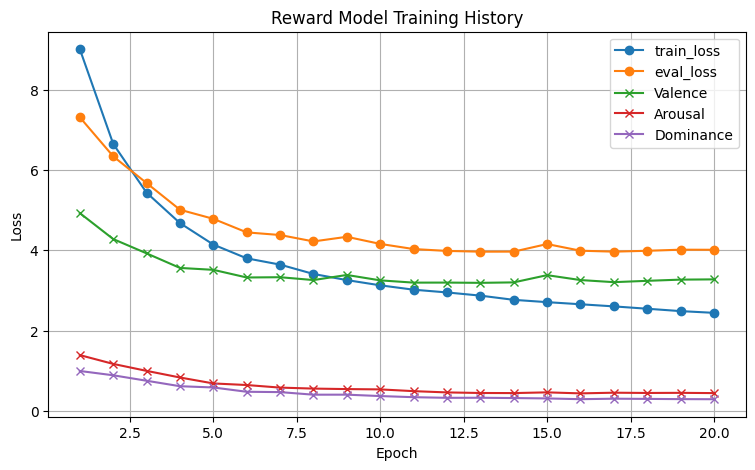

In [9]:
import matplotlib.pyplot as plt

# Convert to DataFrame
history_df = pd.DataFrame(reward_model.training_history)
if history_df.empty:
    print("No training history to plot.")
else:
    # Ensure an epoch column exists
    if 'epoch' not in history_df.columns:
        history_df = history_df.reset_index().rename(columns={'index': 'epoch'})
        history_df['epoch'] = history_df['epoch'] + 1

    plt.figure(figsize=(9,5))
    if 'train_loss' in history_df.columns:
        plt.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='train_loss')
    if 'eval_loss' in history_df.columns:
        plt.plot(history_df['epoch'], history_df['eval_loss'], marker='o', label='eval_loss')
    for col, label in [('eval_loss_V', 'Valence'), ('eval_loss_A', 'Arousal'), ('eval_loss_D', 'Dominance')]:
        if col in history_df.columns:
            plt.plot(history_df['epoch'], history_df[col], marker='x', label=label)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Reward Model Training History')
    plt.legend()
    plt.grid(True)
    plt.show()

Looking at your `RewardModel` implementation, here's how to interpret the loss:

## Loss Computation

Your model trains on **margin prediction** for three dimensions (Valence, Arousal, Dominance):



In [ ]:
# Target margins are log-odds from probabilities
target_margin_V = torch.log(prob_V / (1 - prob_V))  # Range: (-inf, +inf)
target_margin_A = torch.log(prob_A / (1 - prob_A))
target_margin_D = torch.log(prob_D / (1 - prob_D))

# Model predicts margins: score_A - score_B
margin_V = rewards_A[:, 0] - rewards_B[:, 0]
margin_A = rewards_A[:, 1] - rewards_B[:, 1]
margin_D = rewards_A[:, 2] - rewards_B[:, 2]

# Loss is MSE between predicted and target margins
loss_V = MSE(margin_V, target_margin_V)
total_loss = loss_V + loss_A + loss_D



## Interpretation

**Loss Scale:**
- Since you're predicting **log-odds**, the target margins can range from -∞ to +∞
- A probability of 0.5 → margin of 0 (neutral)
- A probability of 0.73 → margin of ~1.0
- A probability of 0.9 → margin of ~2.2
- **MSE loss will be relatively larger** than if you were predicting probabilities [0,1]

**What "Good" Looks Like:**
- **Loss ~1.0**: Model predictions are off by ~1 unit on the log-odds scale (reasonable)
- **Loss ~4.0**: Predictions off by ~2 units (squared: 2² = 4) - moderate error
- **Loss >10.0**: Large systematic errors in margin prediction

**Dimension-Specific Loss:**
- Compare `eval_loss_V`, `eval_loss_A`, `eval_loss_D` to see which dimensions are harder to predict
- Higher loss on one dimension suggests that dimension has more measurement noise or is harder to capture

## Recommendations

**To get more intuitive metrics**, add these to your `evaluate()` method:



In [ ]:
# Add after computing losses in evaluate()
# Convert margins back to probabilities for accuracy metrics
pred_prob_V = torch.sigmoid(margin_V)  # Convert log-odds to probability
true_prob_V = batch['prob_V']

# Binary accuracy (assuming >0.5 means A is better)
correct_V = ((pred_prob_V > 0.5) == (true_prob_V > 0.5)).float().mean()



**Typical benchmark:**
- If your eval loss is **<2.0** per dimension, the model is learning meaningful patterns
- Check if `train_loss` continues decreasing while `eval_loss` plateaus (overfitting)
- Focus on **relative changes**: loss dropping from 3.0 → 1.5 is good progress